# **MÓDULO 21 - Projeto de Credit Score - Árvore de Decisão**


No módulo 17, vocês realizaram a primeira etapa do projeto de crédito de vocês. Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste. Já no módulo 14, aplicaram a base já tratada o algoritmo de Naive Bayes, onde avaliaram os resultados das previsões. Nesse módulo aplicaremos a nossa base o algoritmo da árvore de decisão.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

## Exemplos gráficos em React + Tailwind CSS

Além dos gráficos tradicionais (matplotlib e seaborn) pedidos no exercício, cada etapa gráfica deste notebook tem logo abaixo um **exemplo interativo feito com React e Tailwind CSS**. A célula a seguir apenas define a função `painel_react`, que é chamada nas questões 4, 5, 6 e 8. Os painéis usam o **seu** modelo e os **seus** resultados e precisam de conexão com a internet, porque React e Tailwind são carregados de CDNs. Eles são um complemento e não substituem os gráficos exigidos nas questões.

In [2]:
#@title Painel interativo (React + Tailwind CSS) { display-mode: "form" }
import json, html as _html
from IPython.display import HTML, display

_PAGE_BASE = r"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>Árvore de decisão: exemplos visuais</title>
<script src="https://cdn.tailwindcss.com/3.4.17"></script>
<script src="https://cdn.jsdelivr.net/npm/react@18.3.1/umd/react.production.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/react-dom@18.3.1/umd/react-dom.production.min.js"></script>
<style>
:root{--bg:#f6f7fb;--card:#ffffff;--fg:#14171f;--muted:#5b6475;--line:#d9deea;--accent:#2f5bea;--crit:#e5484d;--ok:#1f9d63;--warn:#d98a1c;
  box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#0f1219;--card:#181c26;--fg:#e9ecf4;--muted:#9aa3b5;--line:#2a3040;--accent:#7b96ff;--crit:#ff6b70;--ok:#3ecf8e;--warn:#e6b450}}
:root[data-theme="dark"]{--bg:#0f1219;--card:#181c26;--fg:#e9ecf4;--muted:#9aa3b5;--line:#2a3040;--accent:#7b96ff;--crit:#ff6b70;--ok:#3ecf8e;--warn:#e6b450}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
body{margin:0;background:var(--bg);color:var(--fg);font-family:system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
.card{background:var(--card);border:1px solid var(--line);border-radius:14px}
.muted{color:var(--muted)}
.tab{border:1px solid var(--line);background:var(--card);color:var(--muted)}
.tab[aria-selected="true"]{background:var(--accent);border-color:var(--accent);color:#fff}
.num{font-variant-numeric:tabular-nums}
.no{cursor:pointer}
.cell{position:relative;border:1px solid var(--line);border-radius:10px;overflow:hidden;min-height:64px}
.cell[aria-pressed="true"]{outline:2px solid var(--fg)}
</style>
</head>
<body>
<div id="root"></div>
<script>
const D = __DADOS__;
const ABA0 = '__ABA__';
const { useState } = React;
const h = React.createElement;
const fmt = (x,d=2) => x.toFixed(d).replace('.',',');
const pct = (x,d=1) => fmt(x*100,d)+'%';
const CORES = ['var(--crit)','var(--warn)','var(--ok)'];
const argmax = a => a.indexOf(Math.max(...a));

function Stat(p){
  return h('div',{className:'card p-3'},
    h('div',{className:'text-xs muted'},p.label),
    h('div',{className:'text-xl font-bold num'},p.value));
}
function Barra(p){
  return h('div',null,
    h('div',{className:'flex justify-between text-xs'},h('span',null,p.nome),h('span',{className:'num muted'},p.texto)),
    h('div',{style:{height:8,background:'var(--line)',borderRadius:4}},
      h('div',{style:{height:8,width:Math.max(0,Math.min(100,p.v*100))+'%',background:p.cor,borderRadius:4}})));
}


/* ---------- aba: matriz de confusão ---------- */
function Matriz(){
  const [q,setQ] = useState('teste');
  const [modo,setModo] = useState('abs');
  const [sel,setSel] = useState([0,0]);
  const cm = D['cm_'+q], K = cm.length, L = D.classes;
  const soma = a => a.reduce((s,v)=>s+v,0);
  const rs = cm.map(soma), tot = soma(rs);
  const ac = cm.reduce((a,r,i)=>a+r[i],0);
  const recs = cm.map((r,i)=>rs[i]?r[i]/rs[i]:0);
  const [i,j] = sel;
  const Seg = (val,cur,set,txt) => h('button',{className:'tab rounded-lg px-3 py-1.5 text-sm','aria-selected':cur===val,onClick:()=>set(val)},txt);
  const grade = h('div',{className:'grid gap-2 items-stretch',style:{gridTemplateColumns:`auto repeat(${K},minmax(0,1fr))`}},
    h('div'),
    L.map((n,c)=>h('div',{key:'h'+c,className:'text-xs muted text-center self-end'},'Previsto: '+n)),
    cm.map((r,a)=>[
      h('div',{key:'l'+a,className:'text-xs muted self-center pr-1',style:{maxWidth:90}},'Real: '+L[a]),
      r.map((v,b)=>{
        const sh = rs[a]?v/rs[a]:0, ok = a===b;
        const op = ok ? 0.1+0.9*sh : (v>0 ? 0.3+0.7*sh : 0.04);
        return h('button',{key:a+'-'+b,className:'cell','aria-pressed':a===i&&b===j,onClick:()=>setSel([a,b])},
          h('span',{className:'absolute inset-0',style:{background:ok?'var(--accent)':'var(--crit)',opacity:op}}),
          h('span',{className:'relative text-lg font-bold num',style:{color:(ok&&sh>0.5)?'#fff':'var(--fg)'}},modo==='abs'?v:pct(sh,0)));
      })
    ])
  );
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-4 grid gap-3 lg:col-span-3 content-start'},
      h('div',{className:'flex flex-wrap gap-2'},
        Seg('treino',q,setQ,'Treino'),Seg('teste',q,setQ,'Teste'),
        h('span',{className:'w-3'}),
        Seg('abs',modo,setModo,'Contagens'),Seg('pct',modo,setModo,'% da linha')),
      grade,
      h('p',{className:'text-sm'},
        h('b',null,cm[i][j]),' cliente(s) da classe real ',h('b',null,L[i]),' foram previstos como ',h('b',null,L[j]),
        i===j?' (acerto).':' (erro).')),
    h('div',{className:'lg:col-span-2 grid gap-3 content-start'},
      h('div',{className:'grid grid-cols-2 gap-3'},
        h(Stat,{label:'Acurácia',value:pct(ac/tot,2)}),
        h(Stat,{label:'Recall macro',value:pct(soma(recs)/K,2)})),
      h('div',{className:'card p-3 grid gap-2'},
        h('div',{className:'text-sm font-semibold'},'Recall por classe (acertos ÷ total real)'),
        recs.map((r,k)=>h(Barra,{key:k,nome:L[k],texto:cm[k][k]+' de '+rs[k]+' ('+pct(r)+')',v:r,cor:CORES[k%3]}))),
      h('p',{className:'text-xs muted'},'Árvore de decisão completa. Na árvore, o treino costuma ficar quase perfeito; compare com o teste para ver o overfitting.')));
}

/* ---------- aba: árvore interativa ---------- */
function Arvore(){
  const [prof,setProf] = useState(Math.min(3,D.profundidade));
  const [sel,setSel] = useState(0);
  const maxP = Math.min(4,D.profundidade);
  let prox = 0; const pos = {};
  const lay = (i,d) => {
    const folha = D.esq[i]===-1 || d>=prof;
    if(folha){ const x = prox++; pos[i] = {x,d,folha:true}; return x; }
    const a = lay(D.esq[i],d+1), b = lay(D.dir[i],d+1);
    pos[i] = {x:(a+b)/2,d,folha:false}; return (a+b)/2;
  };
  lay(0,0);
  const LW=132, LH=96, NW=116, NH=46;
  const W = Math.max(prox,1)*LW+20, H = (prof+1)*LH+10;
  const cx = i => 10+pos[i].x*LW+LW/2, cy = i => 10+pos[i].d*LH+NH/2;
  const ids = Object.keys(pos).map(Number);
  const regra = i => D.esq[i]===-1 ? 'Folha' : D.features[D.feat[i]]+' ≤ '+fmt(D.lim[i],2);
  const s = sel in pos ? sel : 0;
  const dist = D.valores[s];

  const arestas = ids.filter(i=>!pos[i].folha).map(i=>[D.esq[i],D.dir[i]].map((f,k)=>
    h('g',{key:i+'-'+k},
      h('line',{x1:cx(i),y1:cy(i)+NH/2,x2:cx(f),y2:cy(f)-NH/2,style:{stroke:'var(--muted)'},strokeWidth:1.3}),
      h('text',{x:(cx(i)+cx(f))/2+(k?8:-8),y:(cy(i)+cy(f))/2,textAnchor:k?'start':'end',fontSize:10,style:{fill:'var(--muted)'}},k?'não':'sim'))));
  const nos = ids.map(i=>{
    const c = argmax(D.valores[i]);
    return h('g',{key:'n'+i,className:'no',onClick:()=>setSel(i)},
      h('rect',{x:cx(i)-NW/2,y:cy(i)-NH/2,width:NW,height:NH,rx:8,style:{fill:CORES[c%3],stroke:i===s?'var(--fg)':CORES[c%3]},fillOpacity:0.22,strokeWidth:i===s?2.5:1.2}),
      h('text',{x:cx(i),y:cy(i)-3,textAnchor:'middle',fontSize:11,fontWeight:700,style:{fill:'var(--fg)'}},pos[i].folha&&D.esq[i]!==-1?D.classes[c]+' …':(D.esq[i]===-1?D.classes[c]:regra(i))),
      h('text',{x:cx(i),y:cy(i)+13,textAnchor:'middle',fontSize:10,style:{fill:'var(--muted)'}},'n = '+D.amostras[i]));
  });
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-3 lg:col-span-3 grid gap-2 content-start'},
      h('label',{className:'block'},
        h('div',{className:'flex justify-between text-sm'},h('span',{className:'muted'},'Níveis exibidos'),h('span',{className:'font-semibold num'},prof+' de '+D.profundidade)),
        h('input',{type:'range',className:'w-full',min:1,max:maxP,step:1,value:Math.min(prof,maxP),style:{accentColor:'var(--accent)'},onChange:e=>setProf(parseInt(e.target.value))})),
      h('div',{style:{overflowX:'auto'}},
        h('svg',{viewBox:`0 0 ${W} ${H}`,style:{minWidth:Math.min(W,760),width:'100%'},role:'img','aria-label':'Árvore de decisão'},arestas,nos)),
      h('p',{className:'text-xs muted'},'Cada caixa é um nó: a regra de divisão (“sim” vai para a esquerda) e o número de clientes. A cor indica a classe mais comum no nó. Clique para ver os detalhes.')),
    h('div',{className:'lg:col-span-2 grid gap-3 content-start'},
      h('div',{className:'grid grid-cols-3 gap-3'},
        h(Stat,{label:'Profundidade',value:D.profundidade}),
        h(Stat,{label:'Folhas',value:D.folhas}),
        h(Stat,{label:'Nós',value:D.nos})),
      h('div',{className:'card p-3 grid gap-2'},
        h('div',{className:'text-sm font-semibold'},'Nó selecionado'),
        h('div',{className:'text-sm'},D.esq[s]===-1?'Folha: prevê ':'Regra: ',h('b',null,D.esq[s]===-1?D.classes[argmax(dist)]:regra(s))),
        h('div',{className:'text-xs muted'},D.amostras[s]+' clientes | gini = '+fmt(D.gini[s],3)+' (0 = nó puro)'),
        D.classes.map((n,k)=>h(Barra,{key:k,nome:n,texto:pct(dist[k]),v:dist[k],cor:CORES[k%3]}))),
      h('p',{className:'text-sm muted'},'Quanto mais próximo de 0 o gini, mais “puro” é o nó, ou seja, mais clientes da mesma classe. A árvore cresce até as folhas ficarem puras, e por isso tende a decorar o treino.')));
}

/* ---------- aba 2: importância das variáveis ---------- */
function Importancia(){
  const itens = D.features.map((n,i)=>({n,v:D.importancias[i]})).sort((a,b)=>b.v-a.v);
  const topo = itens.slice(0,2);
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-4 lg:col-span-3 grid gap-2 content-start'},
      h('div',{className:'text-sm font-semibold'},'Importância de cada variável na árvore completa'),
      itens.map((it,k)=>h(Barra,{key:it.n,nome:it.n+(k<2?'  ★':''),texto:pct(it.v),v:it.v/(itens[0].v||1),cor:k<2?'var(--accent)':'var(--muted)'}))),
    h('div',{className:'lg:col-span-2 grid gap-3 content-start'},
      h('div',{className:'grid grid-cols-2 gap-3'},
        topo.map((t,k)=>h(Stat,{key:t.n,label:(k+1)+'ª variável',value:t.n}))),
      h(Stat,{label:'Parcela da importância total nas 2 principais',value:pct(topo[0].v+topo[1].v)}),
      h('p',{className:'card p-3 text-sm'},
        'A importância mede o quanto cada variável reduziu a impureza (gini) somando todos os nós em que foi usada. As duas marcadas com ★ são as que treinam a segunda árvore. Importância não significa causa: só mostra o que o modelo usou para separar as classes.')));
}

/* ---------- aba 3: comparação de modelos ---------- */
function Modelos(){
  const M = D.modelos;
  if(!M.length) return h('p',{className:'card p-3 text-sm'},'Execute antes a questão 8 para gerar a tabela de resultados dos modelos.');
  const W=640,H=270,L=44,R=20,T=24,B=48;
  const sy = v => H-B-v*(H-B-T);
  const gw = (W-L-R)/M.length;
  const barra = (v,x,cor,k) => h('g',{key:k},
    h('rect',{x,y:sy(v),width:44,height:sy(0)-sy(v),rx:4,style:{fill:cor}}),
    h('text',{x:x+22,y:sy(v)-5,textAnchor:'middle',fontSize:11,fontWeight:700,style:{fill:'var(--fg)'}},pct(v,1)));
  return h('div',{className:'grid gap-4'},
    h('div',{className:'card p-3'},
      h('svg',{viewBox:`0 0 ${W} ${H}`,className:'w-full',role:'img','aria-label':'Métricas de teste por modelo'},
        [0,0.25,0.5,0.75,1].map(t=>h('g',{key:t},
          h('line',{x1:L,x2:W-R,y1:sy(t),y2:sy(t),style:{stroke:'var(--line)'}}),
          h('text',{x:L-6,y:sy(t)+4,textAnchor:'end',fontSize:11,style:{fill:'var(--muted)'}},Math.round(t*100)+'%'))),
        M.map((m,g)=>h('g',{key:m.nome},
          barra(m.acc_teste,L+g*gw+gw/2-48,'var(--accent)','a'),
          barra(m.rec_teste,L+g*gw+gw/2+4,'var(--ok)','b'),
          h('text',{x:L+g*gw+gw/2,y:H-B+20,textAnchor:'middle',fontSize:11,style:{fill:'var(--fg)'}},m.nome)))),
      h('div',{className:'flex gap-4 text-xs muted px-1'},
        h('span',null,h('b',{style:{color:'var(--accent)'}},'■ '),'Acurácia (teste)'),
        h('span',null,h('b',{style:{color:'var(--ok)'}},'■ '),'Recall macro (teste)'))),
    h('div',{className:'card p-3',style:{overflowX:'auto'}},
      h('table',{className:'w-full text-sm num'},
        h('thead',null,h('tr',{className:'muted text-left'},['Modelo','Acur. treino','Acur. teste','Recall treino','Recall teste'].map(t=>h('th',{key:t,className:'py-1 pr-3 font-medium'},t)))),
        h('tbody',null,M.map(m=>h('tr',{key:m.nome,style:{borderTop:'1px solid var(--line)'}},
          h('td',{className:'py-1 pr-3 font-semibold'},m.nome),
          [m.acc_treino,m.acc_teste,m.rec_treino,m.rec_teste].map((v,k)=>h('td',{key:k,className:'py-1 pr-3'},pct(v,2)))))))),
    h('p',{className:'card p-3 text-sm'},
      'O teste tem apenas ',h('b',null,D.n_teste),' clientes, então um único erro muda a acurácia em cerca de ',h('b',null,fmt(100/D.n_teste,1)+' pontos'),
      '. Diferenças pequenas entre os modelos não são conclusivas; compare também a distância entre treino e teste, que revela overfitting.'));
}

/* ---------- app ---------- */
function App(){
  const [tab,setTab] = useState(ABA0);
  const abas = [['x','Matriz de confusão'],['a','Árvore'],['i','Importância das variáveis'],['c','Comparação de modelos']];
  return h('main',{className:'max-w-5xl mx-auto px-4 py-5 grid gap-4'},
    h('header',null,
      h('h1',{className:'text-xl font-bold'},'Árvore de decisão no score de crédito'),
      h('p',{className:'muted text-sm'},'Exemplos visuais com os resultados reais do seu notebook.')),
    h('div',{className:'flex gap-2 flex-wrap',role:'tablist'},
      abas.map(([k,t])=>h('button',{key:k,role:'tab',className:'tab rounded-lg px-3 py-2 text-sm font-medium','aria-selected':tab===k,onClick:()=>setTab(k)},t))),
    tab==='x'?h(Matriz):tab==='a'?h(Arvore):tab==='i'?h(Importancia):h(Modelos));
}
ReactDOM.createRoot(document.getElementById('root')).render(h(App));
</script>
</body>
</html>
"""

def painel_react(aba="a", altura=800):
    """Exemplo gráfico interativo. aba: x = matriz de confusão, a = árvore, i = importância, c = comparação."""
    T = arvore.tree_
    val = T.value[:, 0, :]
    val = (val / val.sum(axis=1, keepdims=True)).tolist()      # proporção de cada classe por nó
    classes = list(arvore.classes_)
    modelos = []
    if "resultados" in globals():                              # existe depois da questão 8
        modelos = [
            {"nome": nome, "acc_treino": float(r["Acurácia treino"]), "acc_teste": float(r["Acurácia teste"]),
             "rec_treino": float(r["Recall macro treino"]), "rec_teste": float(r["Recall macro teste"])}
            for nome, r in resultados.iterrows()
        ]
    dados = {
        "classes": [NOMES_SCORE.get(c, str(c)) for c in classes],
        "features": list(X_treino.columns),
        "esq": T.children_left.tolist(), "dir": T.children_right.tolist(),
        "feat": [int(f) for f in T.feature], "lim": [float(t) for t in T.threshold],
        "amostras": [int(n) for n in T.n_node_samples], "gini": [float(g) for g in T.impurity],
        "valores": val,
        "profundidade": int(arvore.get_depth()), "folhas": int(arvore.get_n_leaves()), "nos": int(T.node_count),
        "importancias": [float(v) for v in arvore.feature_importances_],
        "cm_treino": confusion_matrix(y_treino, arvore.predict(X_treino), labels=classes).tolist(),
        "cm_teste":  confusion_matrix(y_teste,  arvore.predict(X_teste),  labels=classes).tolist(),
        "modelos": modelos,
        "n_teste": int(len(X_teste)),
    }
    pagina = _PAGE_BASE.replace("__DADOS__", json.dumps(dados)).replace("__ABA__", aba)
    # O iframe isola o CSS do Tailwind e o React do restante do notebook
    display(HTML(
        '<iframe srcdoc="' + _html.escape(pagina, quote=True) + '" '
        f'width="100%" height="{altura}" style="border:1px solid #cfd4e0;border-radius:10px"></iframe>'
    ))

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [ ]:
import os, urllib.request

# Se os CSVs nao estiverem na pasta, baixa do repositorio do GitHub (util no Colab)
BASE_URL = "https://raw.githubusercontent.com/Eduardo-Honorato/modulo-21-arvore-decisao-credit-score/main/"
for arquivo in ["X_treino.csv", "y_treino.csv", "X_teste.csv", "y_teste.csv"]:
    if not os.path.exists(arquivo):
        urllib.request.urlretrieve(BASE_URL + arquivo, arquivo)
        print("Baixado:", arquivo)

In [3]:
# Ajuste os nomes dos arquivos se os seus forem diferentes (mantenha as bases na mesma pasta do notebook).
ARQ_X_TREINO = "X_treino.csv"
ARQ_Y_TREINO = "y_treino.csv"
ARQ_X_TESTE  = "X_teste.csv"
ARQ_Y_TESTE  = "y_teste.csv"

# No M17 o score foi codificado em números: Low = 0, Average = 1, High = 2
NOMES_SCORE = {0: "Low (baixo)", 1: "Average (médio)", 2: "High (alto)"}

def ler(caminho):
    df = pd.read_csv(caminho)
    # remove colunas de índice exportadas sem querer (ex.: "Unnamed: 0")
    return df.loc[:, ~df.columns.str.startswith("Unnamed")]

X_treino, X_teste = ler(ARQ_X_TREINO), ler(ARQ_X_TESTE)
y_treino, y_teste = ler(ARQ_Y_TREINO), ler(ARQ_Y_TESTE)

# 1) Número de linhas
print("Formatos -> X_treino:", X_treino.shape, "| y_treino:", y_treino.shape)
print("Formatos -> X_teste :", X_teste.shape,  "| y_teste :", y_teste.shape)
print("Linhas de X e y iguais no treino?", len(X_treino) == len(y_treino))
print("Linhas de X e y iguais no teste? ", len(X_teste) == len(y_teste))

# 2) y só com o score e X com as demais variáveis
alvo = y_treino.columns[0]
print("\nColunas de y_treino:", list(y_treino.columns), "| y_teste:", list(y_teste.columns))
print(f"'{alvo}' aparece em X_treino?", alvo in X_treino.columns, "| em X_teste?", alvo in X_teste.columns)
print("X_treino e X_teste têm as mesmas colunas?", list(X_treino.columns) == list(X_teste.columns))
print("Colunas não numéricas em X:", list(X_treino.select_dtypes(exclude="number").columns))
print("Valores nulos em X_treino / X_teste:", X_treino.isna().sum().sum(), "/", X_teste.isna().sum().sum())

# y passa a ser uma Series (uma coluna só)
y_treino, y_teste = y_treino.iloc[:, 0], y_teste.iloc[:, 0]

# 3) Balanceamento das classes
print("\nDistribuição de y_treino (%):")
print((y_treino.value_counts(normalize=True).sort_index() * 100).round(2).rename(index=NOMES_SCORE))
print("\nDistribuição de y_teste (%):")
print((y_teste.value_counts(normalize=True).sort_index() * 100).round(2).rename(index=NOMES_SCORE))

# 4) Clientes do teste com cópia idêntica no treino (podem deixar o teste otimista)
copias = X_teste.merge(X_treino.drop_duplicates(), how="inner")
print(f"\nLinhas do teste com cópia idêntica no treino: {len(copias)} de {len(X_teste)}")

Formatos -> X_treino: (270, 7) | y_treino: (270, 1)
Formatos -> X_teste : (33, 7) | y_teste : (33, 1)
Linhas de X e y iguais no treino? True
Linhas de X e y iguais no teste?  True

Colunas de y_treino: ['score_cod'] | y_teste: ['score_cod']
'score_cod' aparece em X_treino? False | em X_teste? False
X_treino e X_teste têm as mesmas colunas? True
Colunas não numéricas em X: []
Valores nulos em X_treino / X_teste: 0 / 0

Distribuição de y_treino (%):
score_cod
Low (baixo)        33.33
Average (médio)    33.33
High (alto)        33.33
Name: proportion, dtype: float64

Distribuição de y_teste (%):
score_cod
Low (baixo)         9.09
Average (médio)    21.21
High (alto)        69.70
Name: proportion, dtype: float64

Linhas do teste com cópia idêntica no treino: 12 de 33


# 2) Explique com suas palavras, qual o passo a passo para a aplicação do algoritmo da árvore de decisão, não esqueça de citar a etapa de avaliação do modelo e também como podemos melhorar nosso modelo.

**Resposta 2:**

O passo a passo que eu seguiria para aplicar uma árvore de decisão:

1. **Preparar os dados:** tratar valores ausentes e inconsistências, transformar as variáveis categóricas em números, separar treino e teste e balancear as classes apenas no treino. Foi o que fiz nos módulos anteriores.
2. **Escolher o algoritmo e os parâmetros:** criar um `DecisionTreeClassifier` com o critério de Gini, que mede a impureza de cada nó, e `random_state=0` para o resultado ser reproduzível.
3. **Treinar o modelo:** com o `fit` nos dados de treino. A árvore escolhe, em cada nó, a variável e o limite que melhor separam as classes, e repete isso até as folhas ficarem puras ou até atingir um limite de profundidade.
4. **Avaliar o modelo:** prever nos dados de treino e de teste e calcular a acurácia, o relatório de classificação e a matriz de confusão. Comparo treino e teste: se o treino for bem melhor que o teste, é sinal de overfitting.
5. **Interpretar:** plotar a árvore, olhar a profundidade e identificar as variáveis mais importantes.

**Como melhorar o modelo:**

- Limitar a complexidade da árvore (`max_depth`, `min_samples_leaf` ou poda com `ccp_alpha`) para reduzir o overfitting.
- Usar apenas as variáveis mais importantes, deixando o modelo mais simples.
- Usar validação cruzada e busca de hiperparâmetros (`GridSearchCV`), para não depender de um único teste com poucos clientes.
- Remover linhas duplicadas antes de separar treino e teste, para o teste não ficar otimista.
- Conseguir mais dados e testar modelos que combinam várias árvores, como o Random Forest.

# 3) Aplique o algortimo da árvore de decisão aos dados de treinamento, utilizando critério de Gini e random state = 0.
Traga a acurácia para o modedlo com os dados de treino.

In [4]:
arvore = DecisionTreeClassifier(criterion="gini", random_state=0)
arvore.fit(X_treino, y_treino)

y_pred_treino = arvore.predict(X_treino)
acc_treino = accuracy_score(y_treino, y_pred_treino)
print(f"Acurácia no treino: {acc_treino:.4f}")

Acurácia no treino: 1.0000


# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

Acurácia no teste: 0.9394

Relatório de classificação (teste):
                 precision    recall  f1-score   support

    Low (baixo)       1.00      1.00      1.00         3
Average (médio)       0.86      0.86      0.86         7
    High (alto)       0.96      0.96      0.96        23

       accuracy                           0.94        33
      macro avg       0.94      0.94      0.94        33
   weighted avg       0.94      0.94      0.94        33



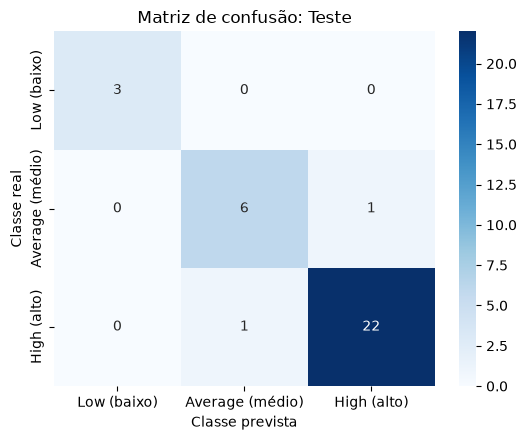


Comparação treino x teste:
          Treino   Teste  Diferença (treino - teste)
Acurácia     1.0  0.9394                      0.0606


In [5]:
rotulos = [NOMES_SCORE.get(c, str(c)) for c in arvore.classes_]

y_pred_teste = arvore.predict(X_teste)
acc_teste = accuracy_score(y_teste, y_pred_teste)
print(f"Acurácia no teste: {acc_teste:.4f}\n")

print("Relatório de classificação (teste):")
print(classification_report(y_teste, y_pred_teste, target_names=rotulos, zero_division=0))

cm = confusion_matrix(y_teste, y_pred_teste, labels=arvore.classes_)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=rotulos, yticklabels=rotulos)
plt.title("Matriz de confusão: Teste")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

comparacao = pd.DataFrame({"Treino": [acc_treino], "Teste": [acc_teste]}, index=["Acurácia"])
comparacao["Diferença (treino - teste)"] = comparacao["Treino"] - comparacao["Teste"]
print("\nComparação treino x teste:")
print(comparacao.round(4))

In [6]:
#@title Exemplo gráfico (React + Tailwind CSS) { display-mode: "form" }
painel_react("x")

C:\Users\eduar\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


**Interpretação da árvore no treino e no teste:**

No treino a árvore acertou **100%**, e no teste **93,94%** (31 de 33 clientes). A diferença é de 6,1 pontos. Uma árvore sem limite de profundidade cresce até as folhas ficarem puras, então acertar tudo no treino já era esperado. Essa queda no teste é um sinal de **overfitting leve**: o modelo se ajustou bem aos dados que viu e generaliza um pouco pior.

No relatório do teste, `Low` teve precisão e recall de 1,00 (3 de 3), `Average` teve 0,86 (6 de 7) e `High` teve 0,96 (22 de 23). Pela matriz de confusão os dois erros foram um `Average` previsto como `High` e um `High` previsto como `Average`, ou seja, entre classes vizinhas. O modelo nunca errou um `Low`.

Ressalvas: o teste tem só 33 clientes, então cada erro vale cerca de 3 pontos, e 12 desses 33 têm uma cópia idêntica no treino, o que deixa o resultado do teste um pouco otimista.

# 5) Plote a árvore de decisão.
É possível fazer uma avaliação visual? Qual a profundidade da árvore?

Profundidade da árvore: 5
Número de folhas: 7
Número total de nós: 13


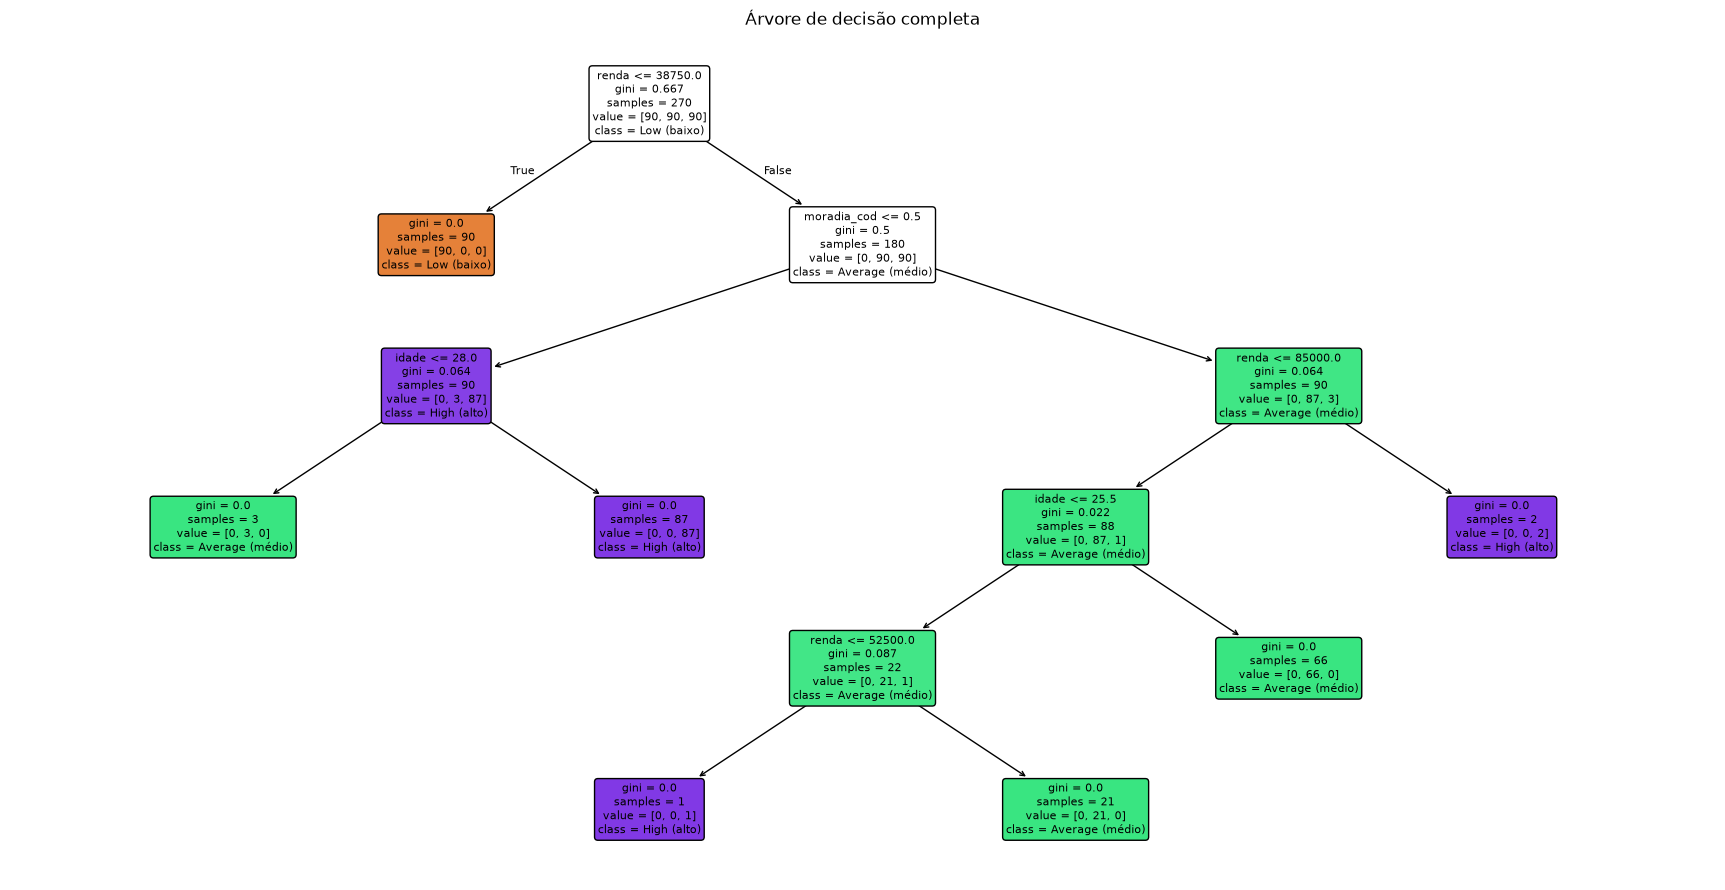

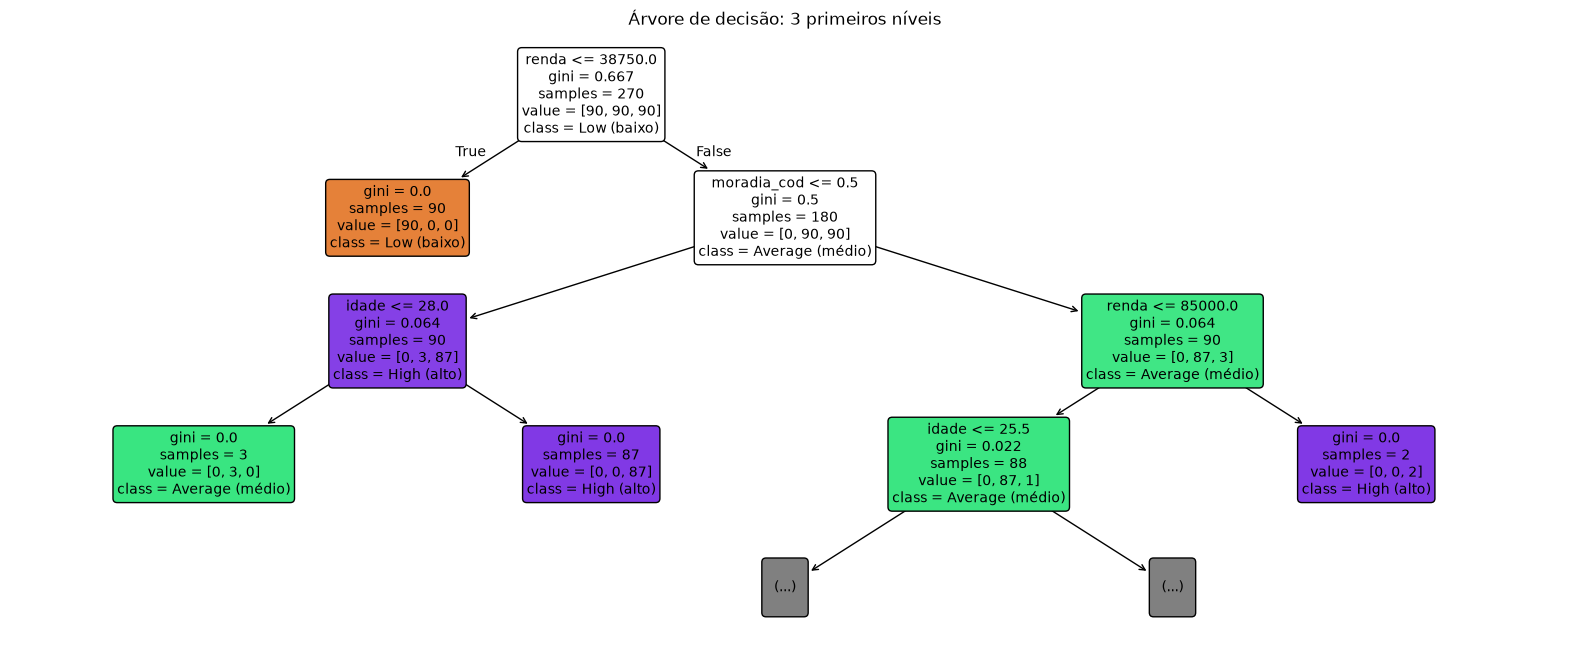

In [7]:
print("Profundidade da árvore:", arvore.get_depth())
print("Número de folhas:", arvore.get_n_leaves())
print("Número total de nós:", arvore.tree_.node_count)

# Árvore completa
plt.figure(figsize=(22, 11))
plot_tree(arvore, feature_names=list(X_treino.columns), class_names=rotulos,
          filled=True, rounded=True, fontsize=8)
plt.title("Árvore de decisão completa")
plt.show()

# Primeiros níveis, mais legíveis
plt.figure(figsize=(20, 8))
plot_tree(arvore, max_depth=3, feature_names=list(X_treino.columns), class_names=rotulos,
          filled=True, rounded=True, fontsize=10)
plt.title("Árvore de decisão: 3 primeiros níveis")
plt.show()

In [8]:
#@title Exemplo gráfico (React + Tailwind CSS) { display-mode: "form" }
painel_react("a")

C:\Users\eduar\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


**Avaliação visual e profundidade:**

Sim, dá para fazer uma avaliação visual: a árvore tem **profundidade 5**, **7 folhas** e **13 nós**, pequena o bastante para ler inteira. A primeira divisão é `renda <= 38.750`, que isola de uma vez todos os 90 clientes `Low` numa folha pura. Depois vem `moradia_cod <= 0,5`, que separa `Average` de `High`, e só então aparecem `idade` e novas divisões de `renda` para refinar poucos casos.

As regras são fáceis de explicar, o que é uma vantagem em crédito: por exemplo, renda até 38.750 leva direto ao score baixo. Por outro lado, alguns ramos finais têm folhas com só 1 a 3 clientes (como a de `idade <= 25,5` e `renda <= 52.500`, com um único cliente). São regras muito específicas, que provavelmente decoram o treino e explicam parte do overfitting.

# 6) Identifique as 2 principais features do modelo.


renda               0.5318
moradia_cod         0.4356
idade               0.0326
filhos              0.0000
genero_cod          0.0000
estado_civil_cod    0.0000
educacao_cod        0.0000
dtype: float64


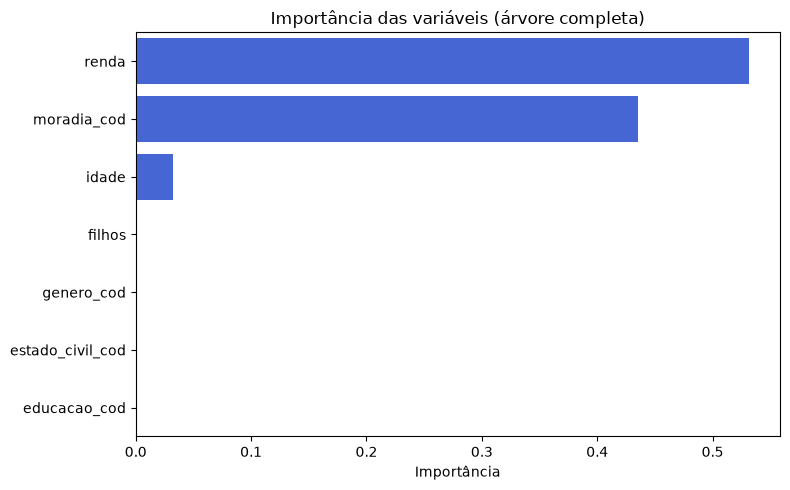


As 2 principais features: ['renda', 'moradia_cod']


In [9]:
importancias = pd.Series(arvore.feature_importances_, index=X_treino.columns).sort_values(ascending=False)
print(importancias.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(x=importancias.values, y=importancias.index, color="#2f5bea")
plt.title("Importância das variáveis (árvore completa)")
plt.xlabel("Importância")
plt.ylabel("")
plt.tight_layout()
plt.show()

top2 = list(importancias.index[:2])
print("\nAs 2 principais features:", top2)

In [10]:
#@title Exemplo gráfico (React + Tailwind CSS) { display-mode: "form" }
painel_react("i")

C:\Users\eduar\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


**As 2 principais features:**

As duas variáveis mais importantes são **`renda` (53,2%)** e **`moradia_cod` (43,6%)**, que juntas somam cerca de **96,7%** da importância. A `idade` aparece com apenas 3,3%, e `filhos`, `genero_cod`, `estado_civil_cod` e `educacao_cod` ficaram com importância zero, ou seja, a árvore não as usou.

Isso faz sentido para um score de crédito: a renda indica a capacidade de pagamento e a moradia pode ser um sinal de estabilidade. A importância mostra o que o modelo usou para separar as classes, mas não prova que essas variáveis causam o score.

# 7) Rode um modelo de árvore de decisão apenas com as 2 principais features encontradas. E avalie os resultados. Para você o desempenho da árvore está melhor que o modelo anterior? Justifique.

In [11]:
arvore2 = DecisionTreeClassifier(criterion="gini", random_state=0)
arvore2.fit(X_treino[top2], y_treino)

acc_treino_2 = accuracy_score(y_treino, arvore2.predict(X_treino[top2]))
y_pred_teste_2 = arvore2.predict(X_teste[top2])
acc_teste_2 = accuracy_score(y_teste, y_pred_teste_2)

print("Relatório de classificação (teste, 2 features):")
print(classification_report(y_teste, y_pred_teste_2, target_names=rotulos, zero_division=0))

comp = pd.DataFrame(
    {"Árvore completa": [acc_treino, acc_teste], "Árvore 2 features": [acc_treino_2, acc_teste_2]},
    index=["Acurácia treino", "Acurácia teste"],
)
print(comp.round(4))
print("\nProfundidade:", arvore.get_depth(), "(completa) x", arvore2.get_depth(), "(2 features)")

Relatório de classificação (teste, 2 features):
                 precision    recall  f1-score   support

    Low (baixo)       1.00      1.00      1.00         3
Average (médio)       0.86      0.86      0.86         7
    High (alto)       0.96      0.96      0.96        23

       accuracy                           0.94        33
      macro avg       0.94      0.94      0.94        33
   weighted avg       0.94      0.94      0.94        33

                 Árvore completa  Árvore 2 features
Acurácia treino           1.0000             0.9963
Acurácia teste            0.9394             0.9394

Profundidade: 5 (completa) x 5 (2 features)


**Árvore com 2 features x árvore completa:**

Com apenas `renda` e `moradia_cod`, a acurácia de treino foi de **99,63%** (antes 100%) e a de teste ficou igual, **93,94%**. O relatório de classificação do teste também ficou idêntico, e a profundidade continuou 5.

Então o desempenho **não ficou melhor, ficou praticamente igual**: o único custo foi um erro a mais no treino (1 em 270), possivelmente por perder a `idade`. Mesmo assim, considero a árvore com 2 features preferível: ela é mais simples, mais fácil de explicar e tem o mesmo resultado no teste. Isso reforça que, nesta base, quase todo o score é explicado por renda e moradia.

# 8) Compare os resultados obtidos com a árvore de decisão com os resultados do Naive Bayes (Exercício módulo 20). Qual parece ter se adequado melhor aos dados e tem melhores resultados de avaliação? Justifique.

In [12]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import recall_score

# Refaz o Naive Bayes do M20 com as mesmas bases, para comparar lado a lado
nb = GaussianNB().fit(X_treino, y_treino)

def resumo(nome, modelo, cols):
    p_tr, p_te = modelo.predict(X_treino[cols]), modelo.predict(X_teste[cols])
    return {
        "Modelo": nome,
        "Acurácia treino": accuracy_score(y_treino, p_tr),
        "Acurácia teste": accuracy_score(y_teste, p_te),
        "Recall macro treino": recall_score(y_treino, p_tr, average="macro"),
        "Recall macro teste": recall_score(y_teste, p_te, average="macro"),
    }

todas = list(X_treino.columns)
resultados = pd.DataFrame([
    resumo("Naive Bayes", nb, todas),
    resumo("Árvore (todas)", arvore, todas),
    resumo("Árvore (2 features)", arvore2, top2),
]).set_index("Modelo")

print(resultados.round(4))

                     Acurácia treino  Acurácia teste  Recall macro treino  \
Modelo                                                                      
Naive Bayes                   0.9926          0.9697               0.9926   
Árvore (todas)                1.0000          0.9394               1.0000   
Árvore (2 features)           0.9963          0.9394               0.9963   

                     Recall macro teste  
Modelo                                   
Naive Bayes                      0.9524  
Árvore (todas)                   0.9379  
Árvore (2 features)              0.9379  


In [13]:
#@title Exemplo gráfico (React + Tailwind CSS) { display-mode: "form" }
painel_react("c")

C:\Users\eduar\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


**Comparação com o Naive Bayes:**

| | Naive Bayes | Árvore (todas) | Árvore (2 features) |
|---|---|---|---|
| Acurácia treino | 99,26% | 100% | 99,63% |
| Acurácia teste | 96,97% | 93,94% | 93,94% |
| Recall macro teste | 95,24% | 93,79% | 93,79% |

O **Naive Bayes teve os melhores resultados no teste** (acurácia 96,97% contra 93,94% e recall macro 95,24% contra 93,79%) e a menor distância entre treino e teste (2,3 pontos contra 6,1 da árvore completa), ou seja, generalizou um pouco melhor e sofreu menos com overfitting. Nesse sentido, ele parece ter se adequado melhor aos dados.

Porém, a diferença é de **um único cliente** (32 acertos contra 31 em 33), então não é conclusiva, e 12 clientes do teste têm cópia no treino. A árvore tem a vantagem da **interpretabilidade**: ela mostra regras claras (renda e moradia), o que é importante em crédito, onde é preciso explicar por que um cliente foi aprovado ou negado. Se só o desempenho importasse eu escolheria o Naive Bayes, mas se a explicação for obrigatória eu ficaria com a árvore, de preferência com a profundidade limitada. O ideal seria confirmar com validação cruzada, em vez de depender de um teste de 33 clientes.